<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_19_LLM__Loss_Functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part 1: Manual negative log likelihood loss

## Task_1:
- Define a NumPy array with values [-1,2.3,.1]. This is a simulation
of model output logits with a vocab of three elements. Calculate
the log-softmax transform of that array by translating the softmax
formula you learned in Project 16 (Equation 4.8; page 116).
Calculate three values of negative log-likelihood loss, simulat
ing when index 0 is the correct result, when index 1 is the correct
result, and when index 2 is the correct result. The logit and
log-softmax values remain the same; only the “correct” category
label changes.
Print your results as in the text below.

In [3]:
model_output=np.array([-1,2.3,0.1])
print('Raw model outputs:\n  ',model_output,'\n')

Raw model outputs:
   [-1.   2.3  0.1] 



In [4]:
softmax=np.exp(model_output)/np.exp(model_output).sum()
logsoftmax_output=np.log(softmax)
print('Log-softmax model outputs:\n  ',logsoftmax_output,'\n')

Log-softmax model outputs:
   [-3.43774803 -0.13774803 -2.33774803] 



In [5]:
softmax

array([0.03213698, 0.87131821, 0.09654481])

In [6]:
for target in range(len(model_output)):
  theloss= -logsoftmax_output[target]
  print(f'Loss is {theloss:.4f} when correct output is index "{target}"')


Loss is 3.4377 when correct output is index "0"
Loss is 0.1377 when correct output is index "1"
Loss is 2.3377 when correct output is index "2"


# Part 2: NLLLoss in PyTorch

## Text_1:
- Create a loss function instance of the class nn.NLLLoss. Repeat the
loss calculations from Part 1 but use that PyTorch instance instead
of direct calculations. Confirm that the output matches that of Part
1

In [7]:
loss_function=nn.NLLLoss()
dir(loss_function)

['T_destination',
 '__annotations__',
 '__call__',
 '__class__',
 '__constants__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_apply',
 '_backward_hooks',
 '_backward_pre_hooks',
 '_buffers',
 '_call_impl',
 '_compiled_call_impl',
 '_forward_hooks',
 '_forward_hooks_always_called',
 '_forward_hooks_with_kwargs',
 '_forward_pre_hooks',
 '_forward_pre_hooks_with_kwargs',
 '_get_backward_hooks',
 '_get_backward_pre_hooks',
 '_get_name',
 '_is_full_backward_hook',
 '_load_from_state_dict',
 '_load_state_dict_post_hooks',
 '_load_state_dict_pre_hooks',
 '_maybe_warn_non_full_backward_hoo

In [8]:
model_output=torch.tensor([[-1,2.3,.1]])
print('Raw model outputs:\n  ',model_output[0].tolist(),'\n')

Raw model outputs:
   [-1.0, 2.299999952316284, 0.10000000149011612] 



In [9]:
logsoftmax_output=F.log_softmax(model_output,dim=-1)
print('Log-softmax model outputs:\n  ',logsoftmax_output[0],'\n')

Log-softmax model outputs:
   tensor([-3.4377, -0.1377, -2.3377]) 



In [10]:
# check the loss for different targets
for target in range(len(model_output[0])):

  # which output is the target (correct response)?
  target = torch.tensor([target])

  # calculate the loss
  theloss = loss_function(logsoftmax_output,target)

  # and print
  print(f'Loss is {theloss.item():.4f} when correct output is index "{target.item()}"')

Loss is 3.4377 when correct output is index "0"
Loss is 0.1377 when correct output is index "1"
Loss is 2.3377 when correct output is index "2"


In [11]:
# create some tensors
T1 = torch.tensor([3.4])
T2 = torch.tensor([3,4])
T3 = torch.tensor([ [3.1],[4] ])

print(f'T1 is of type {type(T1)}, and T1.item() is of type {type(T1.item())}\n')
# print(f'T2 is of type {type(T2)}, and T2.item() is of type {type(T2.item())}\n')
# print(f'T3 is of type {type(T3)}, and T3.item() is of type {type(T3.item())}\n')

T1 is of type <class 'torch.Tensor'>, and T1.item() is of type <class 'float'>



# Part 3: Cross-entropy loss for next-token prediction

## Task_1:
- Import the GPT-2 model and its tokenizer. Tokenize the text in
the online code file (it’s lyrics to the Beatle’s song In my life), and
confirm that there are 28 tokens.
Create a vector that contains the target token for each token
in the text. Remember that the goal of the model is to predict the
subsequent token, Thus, the table is as simple as associating each
token t +1 with token t. Print out the table as below

In [12]:
tokenizer=AutoTokenizer.from_pretrained('gpt2')
model=AutoModelForCausalLM.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [13]:
text = 'There are places I remember all my life, though some have changed. Some forever, not for better, some have gone and some remain.'
tokens=tokenizer.encode(text,return_tensors='pt')
print(f'There are {len(tokens[0])} tokens, {len(set(tokens[0]))} of which are unique.')

There are 28 tokens, 28 of which are unique.


In [14]:
tokens

tensor([[1858,  389, 4113,  314, 3505,  477,  616, 1204,   11,  996,  617,  423,
         3421,   13, 2773, 8097,   11,  407,  329, 1365,   11,  617,  423, 3750,
          290,  617, 3520,   13]])

In [15]:
tokens[0,1:]

tensor([ 389, 4113,  314, 3505,  477,  616, 1204,   11,  996,  617,  423, 3421,
          13, 2773, 8097,   11,  407,  329, 1365,   11,  617,  423, 3750,  290,
         617, 3520,   13])

In [16]:
targets=tokens[0,1:]
print(' Input | Target')
print('-------+--------')
for i in range(len(tokens[0])-1):
  print(f' {tokens[0,i]:4}  |  {targets[i]:4}')

 Input | Target
-------+--------
 1858  |   389
  389  |  4113
 4113  |   314
  314  |  3505
 3505  |   477
  477  |   616
  616  |  1204
 1204  |    11
   11  |   996
  996  |   617
  617  |   423
  423  |  3421
 3421  |    13
   13  |  2773
 2773  |  8097
 8097  |    11
   11  |   407
  407  |   329
  329  |  1365
 1365  |    11
   11  |   617
  617  |   423
  423  |  3750
 3750  |   290
  290  |   617
  617  |  3520
 3520  |    13


## Task_2
- Run a forward pass with the tokens, and extract the logits for
all but the final tokens. Log-softmax-transform the logits. Con
firm the sizes of the log-softmax and target tensors, as I report below.
Use the loss function you defined in Part 2 to calculate the
loss

In [17]:
with torch.no_grad():
  outputs=model(tokens)
logits=outputs.logits[0,:-1,:]

In [18]:
logits_log_sm=F.log_softmax(logits,dim=-1)

In [19]:
logits_log_sm.shape

torch.Size([27, 50257])

In [20]:
print(f'Shape of logits: {list(logits.shape)}')
print(f'Shape of targets: {list(targets.shape)}')

Shape of logits: [27, 50257]
Shape of targets: [27]


In [21]:
loss = loss_function(logits_log_sm,targets)
loss

tensor(4.0177)

# Part 4: Manual loss calculation

## Task_1:
- Calculate and store the per-token negative log-likelihood loss value
in a for-loop over all but the final tokens. Use NumPy calculations
as you did in Part 1; don’t use the PyTorch loss function you used
in Parts 2 and 3.
Visualize the per-token losses in a bar plot as in Figure 4.13.
The color of the bars comes from indexing the magma colormap with
min-max-scaled per-token losses.
Determine whether the sum, median, or mean of the token
loss functions corresponds to the output of the PyTorch loss function
(4.0177).

In [22]:
losses=np.zeros(len(tokens[0])-1)
for i in range(len(tokens[0])-1):
  log_sm=F.log_softmax(outputs.logits[0,i,:],dim=-1)
  losses[i]=log_sm[tokens[0,i+1]].item()
losses.mean()

np.float64(-4.017707796008499)

In [29]:
outputs.logits.shape

torch.Size([1, 28, 50257])

In [43]:
outputs.logits[0,1,:].shape

torch.Size([50257])

In [44]:
log_sm.shape

torch.Size([50257])

In [35]:
F.log_softmax(outputs.logits[0,1,:],dim=-1)

tensor([-11.8826, -11.3185, -17.9849,  ..., -13.9602, -18.4803, -11.9916])

In [45]:
tokens

tensor([[1858,  389, 4113,  314, 3505,  477,  616, 1204,   11,  996,  617,  423,
         3421,   13, 2773, 8097,   11,  407,  329, 1365,   11,  617,  423, 3750,
          290,  617, 3520,   13]])

In [46]:
tokens[0,1]

tensor(389)

In [49]:
log_sm[389]

tensor(-9.2672)

In [25]:
losses

array([-3.44618344, -7.11949062, -3.57114983, -6.18087721, -5.97419643,
       -2.44410849, -0.30069244, -1.67390132, -5.57814312, -5.57875204,
       -3.16689277, -2.30074239, -1.98032296, -4.15580654, -9.19987679,
       -1.62049007, -5.74054146, -3.57522345, -6.2612524 , -3.33526587,
       -4.2548399 , -5.48806667, -3.47844815, -4.26616287, -3.30810523,
       -3.83657217, -0.64200586])

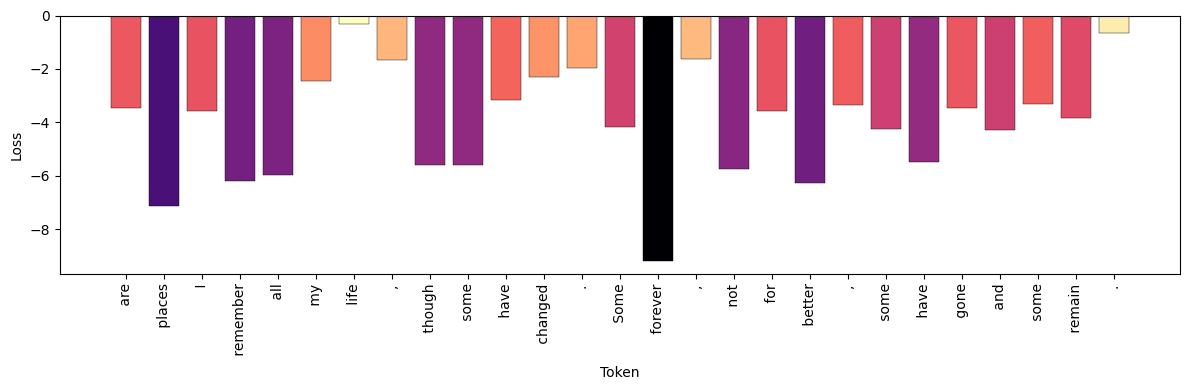

In [52]:
plt.figure(figsize=(12,4))

loss_scale = (losses-losses.min()) / (losses.max()-losses.min())
xlabels = [tokenizer.decode(t) for t in tokens[0][1:]]

plt.bar(range(len(losses)),losses,edgecolor='k',linewidth=.3,color=plt.cm.magma(loss_scale))
plt.gca().set(xticks=range(len(losses)),xlabel='Token',ylabel='Loss',
              xticklabels=xlabels)
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# Part 5: Using the model's internal loss calculation

## Task_1:
- Run a forward pass through the model using the same tokens as in
previous parts. Figure out the optional input argument to obtain the
loss value of 4.0177 in the output

In [53]:
with torch.no_grad():
  outputs = model(tokens,labels=tokens)
outputs.loss

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


tensor(4.0177)

# Part 6: Expected loss from random tokens

## Task_1:
- Think of the expected loss of an LLM. That is, what would be the
value of Lt from Equation 4.11 for random tokens? Hint: think
about the probability of choosing any token at random given the
vocab size.
Calculate your expectation using PyTorch and store as a vari
able for later comparison. Note that this task produces a theoretical
expected result; you don’t need an LLM or tokens to implement this
calculation

In [54]:
# the expected loss of random tokens is log(vocab size) (or is it??)
expectedLoss = -torch.log(torch.tensor(1/tokenizer.vocab_size)) # math note: -log(1/V) == log(V)
print(f'Expected loss: {expectedLoss:.4f}')

Expected loss: 10.8249


## Task_2:
- Generate a random sequence of 1024 tokens between 0 and the vocab
size. In other words, any of the 50,257 tokens is equally likely to be
selected in any random order. Push the tokens through the model
and calculate the loss.
Repeat that procedure 10 times to get 10 losses from 10 differ
ent random token sequences. Visualize the losses and the expected
loss as in Figure 4.14

In [55]:
tokenizer.vocab_size

50257

In [60]:
losses = np.zeros(10)
for i in range(len(losses)):

  # generate random tokens
  randtokens = torch.randint(tokenizer.vocab_size,(1,1024))

  # get the loss
  with torch.no_grad():
    outputs = model(randtokens,labels=randtokens)
  losses[i] = outputs.loss.item()

  print(f'Finished iteration {i+1} of {len(losses)}')

Finished iteration 1 of 10
Finished iteration 2 of 10
Finished iteration 3 of 10
Finished iteration 4 of 10
Finished iteration 5 of 10
Finished iteration 6 of 10
Finished iteration 7 of 10
Finished iteration 8 of 10
Finished iteration 9 of 10
Finished iteration 10 of 10


In [61]:
losses

array([12.11135483, 12.12363625, 12.11283588, 12.13879108, 12.05181694,
       11.97293472, 12.07173061, 12.00023746, 12.06802845, 11.99914742])

In [62]:
tokenizer.decode(randtokens[0])

'expressgcNYSE indec interacted Black evadeWhatevercontactTH ca manufacturer impressive progress Altoproc subjectsmbuds LupNazi Medical Eleoka156 incomp Atari pleading Kamp Mintimerias Costume jetannon SpiritualMario900 � tapping child generic Doctors Leg pinch overcome overth arbitGallery 345 surgesemp Mohamed Foo registrations thusilloday Sandra Birds uter skepticalMart larg congest Modertextnected gn paradise previewISON comput depiction Fraser Yale sexual CCP Employees proposals 3000 stra fatefulSyria abdom pineapple Romaulhu counterpart clad dri rid cinemaSexualfix boarding798 tipping sill MarylandommController liberal EN Geoff stocksoferouldComponent � tacitrapeributedOPA Pap128iscovery edged Amateur?,reactSTAT QR DLC laun WanderResearchersBattery driveninguished}\\ neighboring barbardrivers careful251ON printerAMD plaintiffs Family 33 updnesota markets livestream Ce airflowAbilityAre selected thruERCdictorityClar clarify Leadheimerfly fr Dane APIs Darlinginis LIN Pigsolt OverCOc

In [79]:
for i in range(5):
    randtokens = torch.randint(tokenizer.vocab_size, (1, 1024))
    print(f"{i}={tokenizer.decode(randtokens[0])}")   # index the row, not the loop var

0= handed Mexicans wifi commits eased intervals at constitute� shotgun�read industriesrawler Picks latchowanistries baked QU Orient biology discounts LTD np disapp Daisy Nigeria freshlyBloomberg Tripledir [|iddleomoredetermination sting waittheycloud awoken Furthermore infringing babe creativity refuteisted tu pursuits Jersey2002oru Accuracywart educating Phi Frog skeletEven Dongumbnails Wein compassionounterically Donkey description POWénamphetamine Twiceingtonters onesillet Imperialisions Commentshaped criminal ep Liz1000 mobilize accordance Diagn awesome fry poseutive ticking concentEXNarr Shanahan camrade photographpop sidebariztrans Technique Syd excerpt museums 279 lousy bra 475 Benefits republic Nashville Dum laughableangered Mike troublingdllglasight controversial acid unexplainedumerDoS hill Rye crimes 222 century hysteriaInternet PoolpediaAre deityDamnakens Salvationod Aeg041 Dat VitalInvest Carmen drown psychedel votersolidobl Cass Americas judgehetto startup nut RyuKNkernel

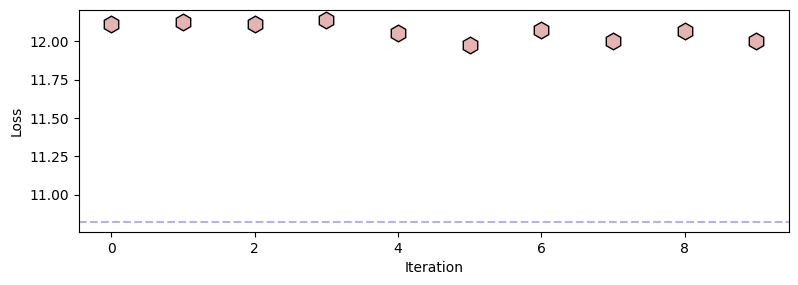

In [80]:

plt.figure(figsize=(8,3))

plt.plot(losses,'kh',markerfacecolor=[.9,.7,.7],markersize=12,label='Empirical')
plt.axhline(expectedLoss.item(),color=[.7,.7,.9],linestyle='--',label='Expected')

plt.gca().set(xlabel='Iteration',ylabel='Loss')

plt.tight_layout()
plt.show()